# Fig. 5f: curation of the "good" units with the paper's model (evoked regime)

**author**: laquitainesteeve@gmail.com

**purpose**: precision and recall of the model that curates the "good" units (>80% agreement score with a ground truth neuron) amongst the sorted single-units of Kilosort 4, for the biophysical simulation in the evoked regime (panel f of the paper). Source data and svg are saved in figures/8_source_data/fig5f/.

**method (the paper's model)**
- kilosort4's sorting extractor was generated with an RTX 5090 GPU, so the results slightly change from the original Tesla V100
- the recording and the sorting are cut to the first 10 minutes, so that the quality metrics that depend on the duration of the recording (firing rate, firing range, ...) are computed over the 600 s that contain the spikes. The paper's original notebook did not cut the recording
- the dataset contains the sorted single-units (rows), their 10 quality metrics (columns) and their quality label ("good": agreement score of at least 0.8 with a ground truth neuron; "bad" otherwise)
- model: binomial generalised linear model (logistic regression) on the 10 quality metrics; 100 random splits of the units (75% train, 25% test); precision and recall on the test units of each split (black dots), their median and 95% confidence interval (orange)
* **published values and Source Data**: the values in the paper (93% precision and 54% recall) and the Source Data in `figures/8_source_data/fig5f/` come from an earlier waveform extraction, which is not stored. The stored waveforms give 0.915 and 0.561, within the 95% CIs: the PCA of the waveform extraction is not exactly repeatable between runs. The notebook therefore reuses the stored waveforms (LOAD_WE = True) and does not overwrite the Source Data unless SAVE_SOURCE_DATA = True; the last cell replots the published Source Data.


In [1]:
# automatically reload notebook
%load_ext autoreload
%autoreload 2

# import built-in packages
import os

# limit BLAS/OpenMP threads per worker, BEFORE numpy is imported (restart the kernel
# if numpy was already imported): the PCA runs ~20x faster than with default threads
# Each worker runs many small PCA fits, each fit makes many BLAS/LAPACK calls, by 
# default each call can use up to 32 threads. We capped that to 1 thread, which 
# substantially removed overhead and sped up compute.
# 2 min instead of 1.5h
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
    
import shutil
import pickle
import copy
import random
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import comparison
from spikeinterface.curation import remove_excess_spikes
from spikeinterface import extract_waveforms
from spikeinterface.postprocessing import compute_principal_components
from spikeinterface.qualitymetrics import compute_quality_metrics as qm
import statsmodels.api as sm
from statsmodels.tools.validation import float_like
import torch
import numpy as np
from matplotlib import pyplot as plt
import sklearn
import seaborn as sns
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import warnings
import spikecurate

# silence irrelevant warnings
warnings.filterwarnings("ignore", message="There is no Probe attached to this recording.*")
warnings.filterwarnings("ignore", message="Versions are not the same.*")

# spikeinterface version
print("Spikeinterface", si.__version__)

# set project path
proj_path = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(proj_path)
os.environ["PYTHONPATH"] = proj_path     # worker processes (joblib) must be able to import the project

# import custom package
# (helpers that read sorting_quality.csv are not in the spikecurate package)
from src.nodes.models.Flc import dataloader

# experiment parameters
EXP = "E"
SORTER = "KS4"

# waveform extraction parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 6
MS_AFTER = 6
SAVE_SOURCE_DATA = False    # True overwrites the published Source Data (earlier extraction) with this run
LOAD_WE = True              # reuse the stored waveforms and PCA when they exist (the PCA is not exactly reproducible between runs)
DURATION_SEC = 600          # 10 minutes recording
MAX_SPIKES_PER_UNIT = 500   # max number of spikes used per unit
SEED = 0
N_COMP_PCA = 5              # number of pca components
SPARSE = True
OVERWRITE = True
WE_JOB_KWARGS = dict(n_jobs=20, chunk_duration="1s", progress_bar=True)
job_kwargs = dict(n_jobs=-1, progress_bar=True)
CHUNKS = 80000

# model parameters
model_prms = {"seeds": np.arange(0,100,1), "scale_data": False}

# recording extractor
RECORDING_PATH = "dataset/00_raw/recording_npx_evoked/"

# kilosort sorting extractor
SORTING_KS4_PATH = "dataset/01_intermediate/sorting/npx_evoked/SortingKS4_10m/"

# ground truth extractors
SORTING_TRUE = "dataset/00_raw/ground_truth_npx_evoked"
SORTING_TRUE_10mn = "dataset/00_raw/ground_truth_npx_evoked_10m"

# waveform extractors
WE_SINGLE_U_PATH = "dataset/01_intermediate/waveforms/npx_evoked/SortingKS4_10m_single_units"

# unit classification
QUALITY_PATH = "dataset/01_intermediate/analysis/sorting_quality/sorting_quality.csv"

# figure parameters
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5 
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# figure legend parameters
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False

Spikeinterface 0.100.8


In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load datasets

* Execution time: 27 ms

### Recording extractor

* Execution time: 

In [3]:
%%time

# load and preprocess recording
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property('location', Recording.get_property('location')[:,:2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
# keep the first 10 min so that the recording duration matches the sorting
# (duration-dependent quality metrics: firing_rate, firing_range, presence_ratio)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
display(Recording)

FrameSliceRecording: 384 channels - 20.0kHz - 1 segments - 12,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 17.17 GiB

CPU times: user 4.3 ms, sys: 44 µs, total: 4.35 ms
Wall time: 4.34 ms


### Ground truth extractor

* Execution time: 

In [4]:
%%time

# load ground truth
SortingTrue = si.load_extractor(SORTING_TRUE)
SortingTrue = SortingTrue.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
SortingTrue.save(folder=SORTING_TRUE_10mn, overwrite=True)
display(SortingTrue)

FrameSliceSorting: 1836 units - 1 segments - 20.0kHz

CPU times: user 703 ms, sys: 16.8 ms, total: 720 ms
Wall time: 720 ms


### Sorting extractor

* Execution time: 20 ms

In [5]:
%%time

# load sorting
Sorting = si.load_extractor(SORTING_KS4_PATH)
Sorting = remove_excess_spikes(Sorting, Recording)
Sorting = Sorting.frame_slice(start_frame=0, end_frame=Recording.get_sampling_frequency() * DURATION_SEC)
display(Sorting)

FrameSliceSorting: 3529 units - 1 segments - 20.0kHz

CPU times: user 942 µs, sys: 996 µs, total: 1.94 ms
Wall time: 1.92 ms


### Waveform extractor (Sorted units)

* Execution time: 1h47

In [6]:
%%time 

# select sorted single-units amongst single- and multi-units (KSLABEL="good" for kilosort4)
single_unit_ids = Sorting.unit_ids[np.where(Sorting.get_property("KSLabel") == "good")[0]]
Sorting_single_units = Sorting.select_units(unit_ids=single_unit_ids)

# save their waveforms and their PCA (the extractor is updated), or load them from a previous run
if LOAD_WE and os.path.exists(WE_SINGLE_U_PATH):
    We_single_u = si.load_waveforms(WE_SINGLE_U_PATH)
else:
    We_single_u = extract_waveforms(Recording, Sorting_single_units, WE_SINGLE_U_PATH, mode="folder", sparse=SPARSE, ms_before=MS_BEFORE,
                        ms_after=MS_AFTER, max_spikes_per_unit=MAX_SPIKES_PER_UNIT, unit_batch_size=CHUNKS,
                        overwrite=OVERWRITE, seed=SEED, **WE_JOB_KWARGS)
    pca = compute_principal_components(waveform_extractor=We_single_u, n_components=N_COMP_PCA, mode="by_channel_local", **WE_JOB_KWARGS)

CPU times: user 24.9 ms, sys: 24.9 ms, total: 49.8 ms
Wall time: 49.7 ms


### Single-unit ids and labels (good/gad)

In [7]:
%%time

# label "good" and "bad" sorted single-units to train the classifier
good_unit_ids, bad_unit_ids = dataloader.get_good_and_bad_units(QUALITY_PATH, exp=EXP, sorter=SORTER)

# report
print("\nSingle-unit ids:", single_unit_ids)
print("\nGood unit ids:", good_unit_ids)
print("\nBad unit ids:", bad_unit_ids)


Single-unit ids: ['98' '109' '114' '118' '135' '136' '138' '149' '153' '161' '166' '169'
 '171' '241' '407' '432' '471' '480' '521' '578' '586' '618' '625' '626'
 '638' '653' '691' '739' '793' '887' '923' '939' '971' '1088' '1117'
 '1120' '1124' '1140' '1149' '1170' '1178' '1180' '1181' '1182' '1183'
 '1184' '1187' '1189' '1190' '1191' '1193' '1194' '1195' '1202' '1205'
 '1206' '1207' '1211' '1212' '1213' '1214' '1216' '1217' '1218' '1221'
 '1224' '1227' '1235' '1239' '1242' '1243' '1244' '1246' '1247' '1248'
 '1249' '1250' '1251' '1255' '1256' '1257' '1260' '1261' '1262' '1264'
 '1265' '1266' '1267' '1271' '1272' '1278' '1280' '1281' '1284' '1293'
 '1294' '1295' '1296' '1300' '1304' '1306' '1308' '1309' '1311' '1312'
 '1315' '1318' '1320' '1324' '1325' '1327' '1330' '1331' '1333' '1335'
 '1336' '1337' '1338' '1339' '1340' '1341' '1347' '1348' '1350' '1351'
 '1353' '1355' '1356' '1359' '1366' '1367' '1370' '1371' '1374' '1375'
 '1376' '1377' '1378' '1382' '1383' '1384' '1385' '1386' '

### Unit-tests

In [8]:
%%time

# sanity check units are correct
single_unit_ids_from_file = dataloader.get_sorted_single_unit_ids_from_file(QUALITY_PATH, EXP, SORTER)
assert len(np.intersect1d(single_unit_ids_from_file, single_unit_ids)) == len(single_unit_ids_from_file), "Units are missing or differ"

CPU times: user 5.06 ms, sys: 6 µs, total: 5.06 ms
Wall time: 5.06 ms


In [9]:
Sorting
len(Sorting.unit_ids[np.where(Sorting.get_property("KSLabel") == "good")[0]])
len(single_unit_ids)

408

## Engineer metrics of cell quality

* Execution time: 2 min

In [10]:
%%time

# engineer a dataset of quality metrics (cols) per cell (rows)
data = spikecurate.load_dataset(single_unit_ids, good_unit_ids, bad_unit_ids, Sorting_single_units, SortingTrue, We_single_u, load_qm_if_exists=False, delta_time=1.3, job_kwargs=WE_JOB_KWARGS)

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/408 [00:00<?, ?it/s]

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

CPU times: user 46.8 s, sys: 19.6 s, total: 1min 6s
Wall time: 1min 37s


In [11]:
%%time 

# measure correlations between features (less is better)
data["dataset"].corr()

CPU times: user 132 µs, sys: 54 µs, total: 186 µs
Wall time: 187 µs


,amplitude_cutoff,firing_range,firing_rate,isi_violations_ratio,rp_contamination,rp_violations,sd_ratio,snr,silhouette,mad_ratio,quality_label
amplitude_cutoff,1.000000,-0.201198,-0.213689,-0.060992,-0.039963,-0.044060,0.468134,0.085723,-0.041508,0.384555,-0.218489
firing_range,-0.201198,1.000000,0.587812,0.135004,0.196219,0.315730,-0.044460,0.100505,0.156593,0.082314,0.141726
firing_rate,-0.213689,0.587812,1.000000,0.364549,0.214179,0.268273,-0.149137,0.230820,0.288442,-0.057770,0.353239
isi_violations_ratio,-0.060992,0.135004,0.364549,1.000000,0.724138,0.606383,-0.071590,0.010787,-0.003334,-0.059276,0.184632
rp_contamination,-0.039963,0.196219,0.214179,0.724138,1.000000,0.908150,-0.030615,0.014586,-0.009527,-0.015253,0.088203
rp_violations,-0.044060,0.315730,0.268273,0.606383,0.908150,1.000000,-0.020876,0.014907,-0.015263,0.003336,0.055228
sd_ratio,0.468134,-0.044460,-0.149137,-0.071590,-0.030615,-0.020876,1.000000,0.205101,-0.012792,0.907022,-0.273151
snr,0.085723,0.100505,0.230820,0.010787,0.014586,0.014907,0.205101,1.000000,0.601262,0.075965,0.499831
silhouette,-0.041508,0.156593,0.288442,-0.003334,-0.009527,-0.015263,-0.012792,0.601262,1.000000,-0.028693,0.583938
mad_ratio,0.384555,0.082314,-0.057770,-0.059276,-0.015253,0.003336,0.907022,0.075965,-0.028693,1.000000,-0.320457


## Model: train/detect >80% accurate units

The paper's model: binomial generalised linear model on the 10 quality metrics (amplitude cutoff, firing range, firing rate, ISI violations ratio, refractory period contamination, refractory period violations, sd ratio, snr, silhouette, mad ratio), evaluated with 100 random splits of the units (75% train, 25% test).

In [12]:
# dataset: 10 quality metrics (units with a missing or infinite metric are dropped)
dataset = data["dataset"].replace([np.inf, -np.inf], np.nan).dropna()
print("units:", len(dataset), "of", len(data["dataset"]), "| good:", int(dataset["quality_label"].sum()))

units: 407 of 408 | good: 105


In [13]:
%%time

# the paper's model: lasso-regularized (L1, inverse strength C=100) binomial GLM on the 10 quality metrics (z-scored), cross-validated with 100 random 75% / 25% splits
model = spikecurate.FractionalLogisticClassifier(data["predictors"], C=100)
results = model.crossval_evaluate(dataset, seeds=np.arange(0, 100, 1), scale_data=True)
stats_ = results["metric_stats"]
print(f"precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (33 outputs left out)

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


precision median 0.915 (95% CI 0.014), recall median 0.561 (95% CI 0.018)
CPU times: user 2min 24s, sys: 0 ns, total: 2min 24s
Wall time: 2min 24s


/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


## Source data

* precision and recall of the model on the test units of each of the 100 splits (fig5f)
* saved as .xlsx with the .svg figure in figures/8_source_data/fig5f/

In [14]:
# source data: precision and recall of the model in each split
df = pd.DataFrame({"seed": np.arange(0, 100, 1), "precision": [m["precision"] for m in results["metric_data"]], "recall": [m["recall"] for m in results["metric_data"]]})
display(df[["precision", "recall"]].agg(["median", "count"]))

,precision,recall
median,0.914855,0.56125
count,100.000000,100.00000


In [15]:
from src.nodes.models.Flc import curation_plots as cp


def plot_source_data(df: pd.DataFrame):
    """Precision and recall of the paper's model on the test units of each cross-validation fold (black dots); median and 95% CI in orange; red dashed line: 0.5.
    Drawn with the geometry of panel f of the paper's figure (Arial 5 pt), see src/nodes/models/Flc/curation_plots.py"""
    return cp.plot_precision_recall(df, "f")

CPU times: user 10.7 ms, sys: 0 ns, total: 10.7 ms
Wall time: 10.7 ms


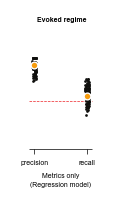

In [16]:
%%time

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

# plot
fig = plot_source_data(df)

# save figure (.svg and .pdf)
if SAVE_SOURCE_DATA:    # the published Source Data come from an earlier extraction (see the description)
    os.makedirs("figures/8_source_data/fig5f", exist_ok=True)
    fig.savefig("figures/8_source_data/fig5f/fig5f.svg", **savefig_cfg)

# save source data
if SAVE_SOURCE_DATA:
    df.to_excel("figures/8_source_data/fig5f/fig5f.xlsx", index=False)

CPU times: user 41.3 ms, sys: 0 ns, total: 41.3 ms
Wall time: 41.2 ms


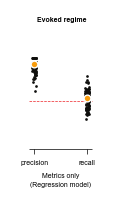

In [17]:
%%time

# check: replot from the saved source data
df = pd.read_excel("figures/8_source_data/fig5f/fig5f.xlsx")
fig = plot_source_data(df)